Supervised Learning on Census Income - 2026-11-01 - jacgra1349

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, roc_auc_score
from IPython.display import display, Markdown

# Load the Census Income dataset
data = pd.read_csv("/content/census_income_dataset.csv")

display(Markdown("### Load and Explore the Census Income Dataset"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

print("Dataset Information:")
data.info()

print("\nDataset Description:")
print(data.describe())

### Load and Explore the Census Income Dataset

Date: 2026-11-01

Student ID: jacgra1349

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB

Dataset Description:
                age        fnlwgt  education-num  

In [2]:
display(Markdown("### Data Preprocessing"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

# Correct missing values
categorical_columns = data.select_dtypes(include=['object']).columns

for column in categorical_columns:
    if column != 'income':
        data[column] = data[column].fillna(data[column].mode()[0])

# Identify and remove duplicate rows
print("Duplicate rows before removal:", data.duplicated().sum())

data = data.drop_duplicates()

print("Duplicate rows after removal:", data.duplicated().sum())

# Perform one-hot encoding on categorical features
categorical_features = data.select_dtypes(include=['object']).columns.drop('income')
data = pd.get_dummies(data, columns=categorical_features)

# Convert income to binary
data['income'] = data['income'].apply(lambda x: 1 if x == '>50K' else 0)

# Separate features and target
X = data.drop('income', axis=1)
y = data['income']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

### Data Preprocessing

Date: 2026-11-01

Student ID: jacgra1349

Duplicate rows before removal: 29
Duplicate rows after removal: 0
Training data shape: (34169, 108)
Testing data shape: (14644, 108)


In [3]:
display(Markdown("### K-Nearest Neighbors (KNN)"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

# Initialize and train the KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Make predictions on the test set
y_pred_knn = knn.predict(X_test)

# Display predictions
print("First 20 predicted values:")
print(y_pred_knn[:20])

print("\nFirst 20 actual values:")
print(y_test.values[:20])

### K-Nearest Neighbors (KNN)

Date: 2026-11-01

Student ID: jacgra1349

First 20 predicted values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 actual values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0]


In [4]:
display(Markdown("### KNN Model Evaluation"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred_knn)
precision = precision_score(y_test, y_pred_knn, zero_division=0)
recall = recall_score(y_test, y_pred_knn, zero_division=0)
f1 = f1_score(y_test, y_pred_knn, zero_division=0)

print("Accuracy Score:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred_knn)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

### KNN Model Evaluation

Date: 2026-11-01

Student ID: jacgra1349

Accuracy Score: 0.8292816170445233
Precision: 0.4483394833948339
Recall: 0.20351758793969849
F1 Score: 0.2799539170506912

Confusion Matrix:
[[11658   598]
 [ 1902   486]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     12256
           1       0.45      0.20      0.28      2388

    accuracy                           0.83     14644
   macro avg       0.65      0.58      0.59     14644
weighted avg       0.79      0.83      0.80     14644



In [5]:
display(Markdown("### KNN Hyperparameter Tuning"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Initialize GridSearchCV with the KNN model and parameter grid
grid_search_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    refit=True,
    verbose=2,
    cv=5
)

# Fit the model to the training data
grid_search_knn.fit(X_train, y_train)

# Display the best parameters and best score
print(f"Best Parameters: {grid_search_knn.best_params_}")
print(f"Best Score: {grid_search_knn.best_score_}")

### KNN Hyperparameter Tuning

Date: 2026-11-01

Student ID: jacgra1349

Fitting 5 folds for each of 24 candidates, totalling 120 fits
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   5.6s
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   5.3s
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   2.8s
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   3.2s
[CV] END ...metric=euclidean, n_neighbors=3, weights=uniform; total time=   2.4s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   2.6s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   2.6s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   2.6s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   2.9s
[CV] END ..metric=euclidean, n_neighbors=3, weights=distance; total time=   2.4s
[CV] END ...metric=euclidean, n_neighbors=5, weights=uniform; total time=   2.6s
[CV] END ...metric=euclidean, n_neighbors=5, we

In [6]:
display(Markdown("### Tuned KNN Model"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

# Make predictions with the best estimator
y_pred_knn_tuned = grid_search_knn.best_estimator_.predict(X_test)

# Display the best parameters
print("Best Parameters:")
print(grid_search_knn.best_params_)

print("\nBest Cross-Validation Score:")
print(grid_search_knn.best_score_)

# Calculate performance metrics
tuned_accuracy = accuracy_score(y_test, y_pred_knn_tuned)
tuned_precision = precision_score(y_test, y_pred_knn_tuned, zero_division=0)
tuned_recall = recall_score(y_test, y_pred_knn_tuned, zero_division=0)
tuned_f1 = f1_score(y_test, y_pred_knn_tuned, zero_division=0)

print("\nTuned KNN Accuracy:", tuned_accuracy)
print("Tuned KNN Precision:", tuned_precision)
print("Tuned KNN Recall:", tuned_recall)
print("Tuned KNN F1 Score:", tuned_f1)

# Display the confusion matrix
tuned_cm = confusion_matrix(y_test, y_pred_knn_tuned)

print("\nTuned KNN Confusion Matrix:")
print(tuned_cm)

print("\nTuned KNN Classification Report:")
print(classification_report(y_test, y_pred_knn_tuned))

### Tuned KNN Model

Date: 2026-11-01

Student ID: jacgra1349

Best Parameters:
{'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'uniform'}

Best Cross-Validation Score:
0.8457372960782987

Tuned KNN Accuracy: 0.8442365473914231
Tuned KNN Precision: 0.5704874835309618
Tuned KNN Recall: 0.18132328308207704
Tuned KNN F1 Score: 0.2751827136955831

Tuned KNN Confusion Matrix:
[[11930   326]
 [ 1955   433]]

Tuned KNN Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91     12256
           1       0.57      0.18      0.28      2388

    accuracy                           0.84     14644
   macro avg       0.71      0.58      0.59     14644
weighted avg       0.81      0.84      0.81     14644



### Confusion Matrix Heatmap

Date: 2026-11-01

Student ID: jacgra1349

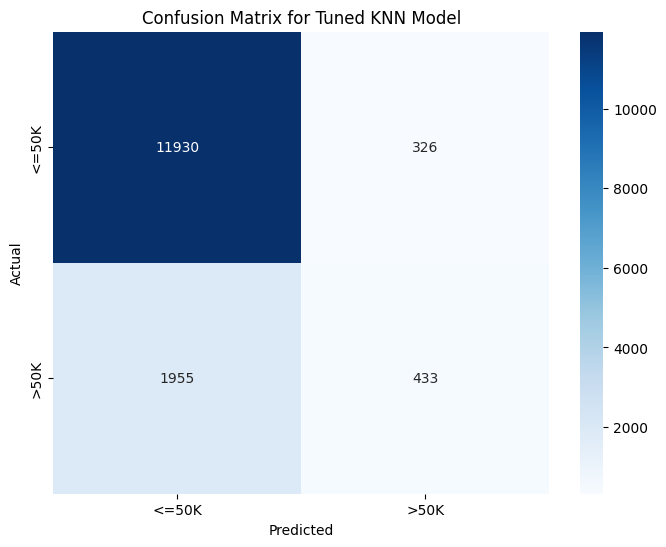

In [7]:
display(Markdown("### Confusion Matrix Heatmap"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

plt.figure(figsize=(8, 6))

sns.heatmap(
    tuned_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['<=50K', '>50K'],
    yticklabels=['<=50K', '>50K']
)

plt.title('Confusion Matrix for Tuned KNN Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### ROC Curve and AUC for Tuned KNN

Date: 2026-11-01

Student ID: jacgra1349

AUC Score: 0.6642801146725796


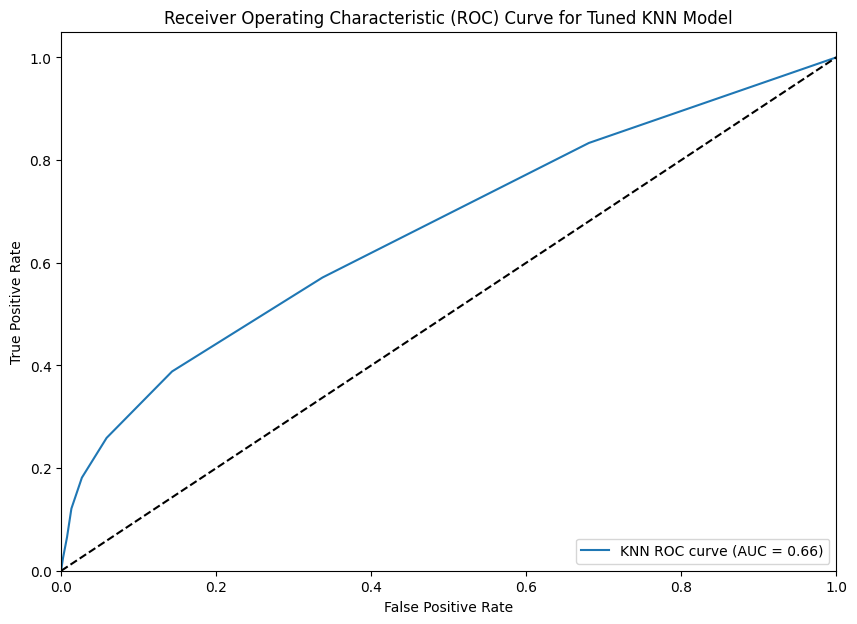

In [8]:
from sklearn.metrics import roc_curve, roc_auc_score

display(Markdown("### ROC Curve and AUC for Tuned KNN"))
display(Markdown("Date: 2026-11-01"))
display(Markdown("Student ID: jacgra1349"))

# Calculate prediction probabilities
y_pred_proba = grid_search_knn.best_estimator_.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_pred_proba)

print("AUC Score:", auc_score)

# Plot ROC curve
plt.figure(figsize=(10, 7))

plt.plot(
    fpr,
    tpr,
    label=f'KNN ROC curve (AUC = {auc_score:.2f})'
)

plt.plot([0, 1], [0, 1], 'k--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Tuned KNN Model')
plt.legend(loc="lower right")
plt.show()